# E06 · Pseudo-labelling with Kaggle images (variants a, b, c)

`06_kaggle_confidence` showed that the remaining errors sit mostly in the vegetation and crop classes and in mixed
scenes EuroSAT rarely contains. No colour correction reaches those. **Pseudo-labelling** adds Kaggle images to the
training set, labelled by the best model so far, so the model sees real Level-2A images during training.

Setup as `E04_contrast_aug` (EfficientNet-B0, 12 bands, `hist_split`, contrast/brightness augmentation, same
hyperparameters), AdaBN balanced at the end. Validation and the internal test set stay pure EuroSAT.

| Variant | Labels from | Selection | Images | Repeats per epoch |
|---|---|---|---|---|
| **E06a** · round 1 | E04 + AdaBN (`artifacts/kaggle_confidence.csv`) | all 8 views agree, ≥ 3 of 4 models agree, 150 most confident per class | 1,500 | 1 |
| **E06b** · round 2 | E06a + AdaBN | all 8 views agree, up to 250 most confident per class | 2,314 | 1 |
| **E06c** · round 2, 2× | same as E06b | same as E06b | 2,314 | 2 |

**Why per class.** A global threshold (conf ≥ 0.8) would keep 1,014 SeaLake but only 15 PermanentCrop and 21 Pasture
images, so the model would drift away from the hard classes. The same number per class also keeps the water share close
to training, the lesson from `E03_adabn`.

**Risk:** wrong pseudo-labels are learned as truth. The selection keeps only images where the predictions are stable,
and the internal test set (EuroSAT) shows whether the model got worse at the original task.

> **Note on E06b/E06c.** The selection was meant to also require that E06a *without* AdaBN agrees. Because of a bug in
> `find_run` at the time (fixed on 2026-10-13), that check loaded E06a *with* AdaBN, the labelling model itself, so it
> was always true. The settings below reproduce what was actually trained (`CHECK_RUN` = `LABEL_RUN`).

**Train or load.** `LOAD_RUNS` points every variant to its saved run: the notebook loads the weights and
recomputes all results and submission files without training. Set one entry to `None` to train that variant again
(about 25 minutes each on an M4 GPU; creates new run folders).

## 1 · Setup and data

In [1]:
import json
import sys
from dataclasses import asdict, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, TEST_BANDS
from src.experiment import (add_pseudo_labels, adabn_balanced, class_mix, compare_variants, find_run,
                            finish_run, kaggle_monitor, load_experiment_data, load_saved_model,
                            plot_class_mix, plot_variant_curves, pseudo_label_summary,
                            pseudo_labels_from_run, pseudo_labels_from_table, view_agreement)
from src.models import MEDIUM_TRACK_LIMIT, build_model
from src.plot_style import apply_style
from src.training import (Normalizer, TrainConfig, adapt_batchnorm, fit, load_run, new_run_dir,
                          predict_proba, predict_views, write_submission)
from src.utils import describe_device, get_device, seed_everything

apply_style()

# ---- Experiment settings ---------------------------------------------------------------
NOTEBOOK = "E06_pseudo_labelling"
LOAD_RUNS = {   # saved runs; None = train this variant again
    "E06a": "runs/2026-10-12_1514_pseudo_label_contrast_aug_hist_split_effb0",
    "E06b": "runs/2026-10-12_1554_pseudo_label_r2_contrast_aug_hist_split_effb0",
    "E06c": "runs/2026-10-12_1625_pseudo_label_r2_x2_contrast_aug_hist_split_effb0",
}
# Round 1 (E06a)
PSEUDO_LABELS = "artifacts/kaggle_confidence.csv"   # from notebooks/data/06_kaggle_confidence
PL1_MIN_MODEL_AGREE = 3   # of 4 models (E04, E05a-c, each + AdaBN)
PL1_PER_CLASS = 150
# Round 2 (E06b, E06c)
LABEL_RUN = "adabn_balanced_pseudo_label_contrast_aug_hist_split_effb0"   # E06a + AdaBN, 70.71%
CHECK_RUN = LABEL_RUN    # reproduces the runs (see the note above); intended: "pseudo_label_contrast_aug_hist_split_effb0"
PL2_PER_CLASS = 250
MODEL = "efficientnet_b0"
BANDS = list(TEST_BANDS)
SEED = 42
cfg = TrainConfig(epochs=20, batch_size=128, lr=1e-3, weight_decay=1e-4,
                  label_smoothing=0.1, patience=5, augment=True,
                  photometric={"contrast": (0.9, 1.5), "band_contrast": (0.9, 1.15),
                               "brightness": (0.93, 1.07), "p": 0.8})   # as in E04
# -----------------------------------------------------------------------------------------

seed_everything(SEED)
device = get_device()              # CUDA > Apple GPU (MPS) > CPU
print("Device:", describe_device(device))
results = {}                        # variant -> RunResult, compared at the end

data = load_experiment_data(BANDS, ["hist_split"], device)
print(data.summary())


def train_or_load(variant, tr_images, tr_labels):
    """Train on EuroSAT + pseudo-labels, or load the saved run."""
    if LOAD_RUNS[variant]:
        model, normalizer, history = load_saved_model(LOAD_RUNS[variant], device)
        return model, normalizer, history, None
    seed_everything(SEED)
    normalizer = Normalizer.fit(data.X_tr)
    model = build_model(MODEL, bands=BANDS, pretrained=True).to(device)
    history, best_state = fit(model, tr_images, tr_labels, data.va_images, data.va_labels,
                              normalizer, cfg, monitor=kaggle_monitor(data, normalizer))
    return model, normalizer, history, best_state


def base_config(variant, run_name, description, pseudo_labels):
    return {"run_name": run_name, "description": description, "notebook": NOTEBOOK, "variant": variant,
            "model": MODEL, "bands": BANDS, "corrections": ["hist_split"], "train": asdict(cfg),
            "split": "split_seed42", "pseudo_labels": pseudo_labels}

Device: Apple GPU (MPS)


train 18,900  val 4,050  internal test 4,050  Kaggle test 4,232


## 2 · E06a · Round 1: labels from E04 + AdaBN

From `artifacts/kaggle_confidence.csv` (`06_kaggle_confidence`): all 8 views agree, at least 3 of the 4 models
(E04, E05a–c, each with AdaBN) agree, then the 150 most confident images per predicted class.

In [2]:
table1, idx1 = pseudo_labels_from_table(PROJECT_ROOT / PSEUDO_LABELS, PL1_MIN_MODEL_AGREE, PL1_PER_CLASS)
assert (table1["test_id"].values == data.test_ids["test_id"].values).all()
tr_images, tr_labels, _ = add_pseudo_labels(data, table1, idx1, repeat=1)
pseudo_label_summary(table1, idx1)

Pseudo-labelled Kaggle images: 1,500 of 4,232, used 1x (7.4% of the training set, 20,400 images)


,n,min_conf,mean_conf
pred,,,
AnnualCrop,150,0.740,0.864
Forest,150,0.851,0.871
HerbaceousVegetation,150,0.681,0.781
Highway,150,0.854,0.874
Industrial,150,0.713,0.838
Pasture,150,0.621,0.756
PermanentCrop,150,0.671,0.752
Residential,150,0.848,0.859
River,150,0.725,0.804


In [3]:
model, normalizer, history, best_state = train_or_load("E06a", tr_images, tr_labels)
results["E06a"] = finish_run(model, normalizer, history, best_state, data, variant="E06a", load_run=LOAD_RUNS["E06a"],
    device=device, seed=SEED, param_limit=MEDIUM_TRACK_LIMIT,
    config=base_config("E06a", "pseudo_label_contrast_aug_hist_split_effb0",
                       "hist_split + contrast aug + pseudo-labelled Kaggle images",
                       {"source": PSEUDO_LABELS, "min_model_agree": PL1_MIN_MODEL_AGREE,
                        "per_class": PL1_PER_CLASS, "n_images": int(len(idx1))}))

Loaded runs/2026-10-12_1514_pseudo_label_contrast_aug_hist_split_effb0 (20 epochs): no training


E06a: internal test 98.96% · Kaggle confidence 82.7% (with AdaBN 77.9%) · 4,022,950 parameters
  run folders: runs/2026-10-12_1514_pseudo_label_contrast_aug_hist_split_effb0, runs/2026-10-12_1515_adabn_balanced_pseudo_label_contrast_aug_hist_split_effb0


## 3 · E06b and E06c · Round 2: labels from E06a + AdaBN

E06a is more confident on Kaggle images than E04 (82.7% vs 73.6%), so more images of the hard classes pass the filter:
Pasture 190 instead of about 160 candidates. Classes with fewer than 250 candidates use all of them, so their weakest
labels go down to about 0.45 confidence. E06c uses the same images twice per epoch, so the Kaggle images weigh more
against the 18,900 EuroSAT images (19.7% instead of 10.9% of the training set).

In [4]:
table2, idx2 = pseudo_labels_from_run(LABEL_RUN, CHECK_RUN, PL2_PER_CLASS, data, device)
pd.DataFrame({"candidates": table2[table2["view_agree"] & table2["check_agree"]]["pred"].value_counts()}) \
    .join(pseudo_label_summary(table2, idx2)).reindex(CLASSES)

,candidates,n,min_conf,mean_conf
pred,,,,
AnnualCrop,269,250,0.684,0.825
Forest,340,250,0.860,0.890
HerbaceousVegetation,262,250,0.688,0.838
Highway,288,250,0.793,0.845
Industrial,193,193,0.457,0.847
Pasture,190,190,0.580,0.806
PermanentCrop,232,232,0.453,0.794
Residential,322,250,0.814,0.860
River,199,199,0.567,0.845


In [5]:
for variant, repeat, run_name, extra in [("E06b", 1, "pseudo_label_r2_contrast_aug_hist_split_effb0", ""),
                                         ("E06c", 2, "pseudo_label_r2_x2_contrast_aug_hist_split_effb0", ", 2x")]:
    tr_images, tr_labels, _ = add_pseudo_labels(data, table2, idx2, repeat=repeat)
    model, normalizer, history, best_state = train_or_load(variant, tr_images, tr_labels)
    results[variant] = finish_run(model, normalizer, history, best_state, data, variant=variant,
        load_run=LOAD_RUNS[variant], device=device, seed=SEED, param_limit=MEDIUM_TRACK_LIMIT,
        config=base_config(variant, run_name, f"hist_split + contrast aug + pseudo-labels round 2 (from E06a + AdaBN){extra}",
                           {"label_run": LABEL_RUN, "check_run": CHECK_RUN, "per_class": PL2_PER_CLASS,
                            "repeat": repeat, "n_images": int(len(idx2))}))
    del tr_images, tr_labels

Pseudo-labelled Kaggle images: 2,314 of 4,232, used 1x (10.9% of the training set, 21,214 images)
Loaded runs/2026-10-12_1554_pseudo_label_r2_contrast_aug_hist_split_effb0 (20 epochs): no training


E06b: internal test 98.81% · Kaggle confidence 84.7% (with AdaBN 81.4%) · 4,022,950 parameters
  run folders: runs/2026-10-12_1554_pseudo_label_r2_contrast_aug_hist_split_effb0, runs/2026-10-12_1555_adabn_balanced_pseudo_label_r2_contrast_aug_hist_split_effb0


Pseudo-labelled Kaggle images: 2,314 of 4,232, used 2x (19.7% of the training set, 23,528 images)
Loaded runs/2026-10-12_1625_pseudo_label_r2_x2_contrast_aug_hist_split_effb0 (20 epochs): no training


E06c: internal test 98.94% · Kaggle confidence 85.3% (with AdaBN 81.6%) · 4,022,950 parameters
  run folders: runs/2026-10-12_1625_pseudo_label_r2_x2_contrast_aug_hist_split_effb0, runs/2026-10-12_1626_adabn_balanced_pseudo_label_r2_x2_contrast_aug_hist_split_effb0


## 4 · Comparison

Where do the predictions change compared with the model that produced the labels: on the images it was unsure about
(where the errors are) or on the confident ones (where it was probably right)?

In [6]:
label_source = {"E06a": (table1["pred"].values, table1["conf"].values),          # E04 + AdaBN
                "E06b": (table2["pred"].values, table2["conf"].values),          # E06a + AdaBN
                "E06c": (table2["pred"].values, table2["conf"].values)}
summary = compare_variants(results)
for k, r in results.items():
    ref_pred, ref_conf = label_source[k]
    changed = np.array(CLASSES)[r.prob_ada.argmax(1)] != ref_pred
    summary.loc[k, "changed: label model unsure (%)"] = changed[ref_conf < 0.6].mean() * 100
    summary.loc[k, "changed: label model confident (%)"] = changed[ref_conf >= 0.6].mean() * 100
summary.round(2)

,description,internal test (%),confidence (%),view agreement (%),Kaggle public (%),changed: label model unsure (%),changed: label model confident (%)
E06a,hist_split + contrast aug + pseudo-labelled Ka...,98.962963,77.931183,78.426276,70.706,38.05,1.56
E06b,hist_split + contrast aug + pseudo-labels roun...,98.814815,81.440994,83.648393,None,33.99,1.31
E06c,hist_split + contrast aug + pseudo-labels roun...,98.938272,81.593964,84.215501,71.502,36.95,1.36


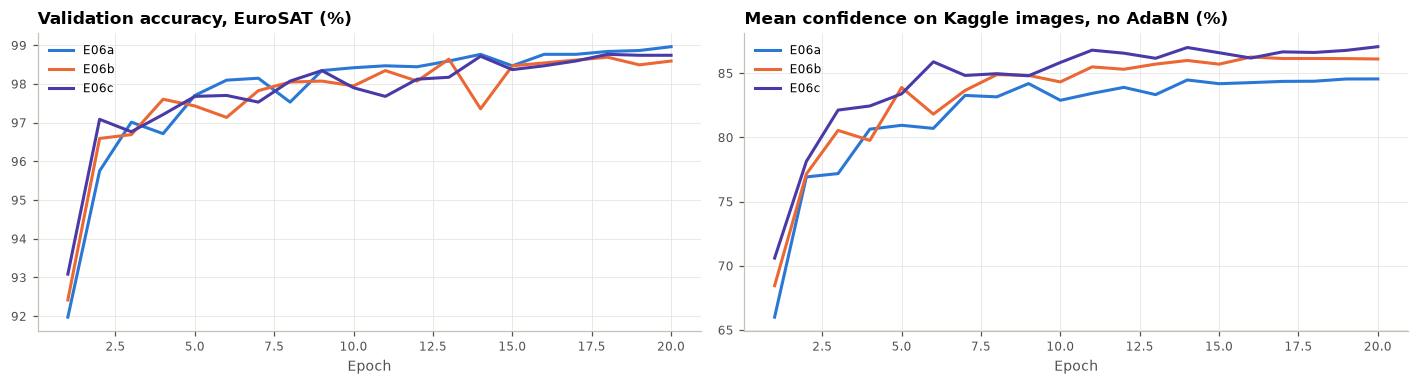

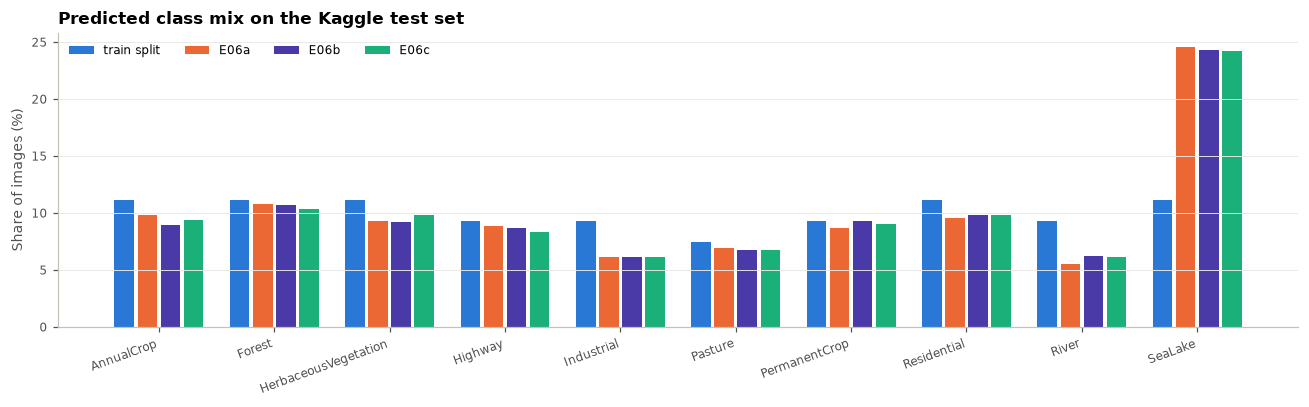

In [7]:
plot_variant_curves(results)
plot_class_mix(pd.DataFrame({"train split": class_mix(np.eye(10)[data.y_tr]),
                             **{k: class_mix(r.prob_ada) for k, r in results.items()}}))

## 5 · Conclusion

| Variant | Pseudo-labels | Internal test | Confidence | View agreement | Kaggle public |
|---|---|---|---|---|---|
| E04 + AdaBN (reference) | – | 98.77% | 73.6% | 72.5% | 68.18% |
| E06a + AdaBN | 1,500 from E04, 1× | 98.96% | 77.9% | 78.4% | 70.71% |
| E06b + AdaBN | 2,314 from E06a, 1× | 98.81% | 81.4% | 83.6% | not submitted |
| **E06c + AdaBN** | 2,314 from E06a, 2× | 98.94% | 81.6% | 84.2% | **71.50%** |

- **Pseudo-labelling is the largest gain since E04:** +2.5 points in round 1, +0.8 in round 2. EuroSAT accuracy is
  unchanged, so the Kaggle images don't hurt the original task.
- **The changes are where the errors are:** 38% (E06a) and about 35% (E06b/c) of the images the label model was unsure
  about get a new class, but only 1.3–1.6% of the confident ones. Most changes are within the vegetation/crop classes.
- **Per-class selection matters:** a global threshold would have trained mostly on SeaLake.
- **AdaBN still helps after pseudo-labelling.** Without AdaBN, the models are more confident, but the crop skew
  (PermanentCrop > AnnualCrop) comes back, as in E04. Only the AdaBN versions were submitted.
  Checked on Kaggle later (2026-10-25): E06c 71.08% without AdaBN vs 71.50% with; E06b 70.99% without.
- **The 2× weight changes little:** E06b and E06c agree on 94.8% of the Kaggle images; E06c is slightly ahead on every
  label-free measure, so only E06c was submitted.

**Next:** a round 3 should add a minimum confidence of about 0.6 (four classes used labels down to 0.45 in round 2).
E06c is the base of `E07` and `E08`.